Visualizations: https://www.naftaliharris.com/blog/visualizing-k-means-clustering/

## Algorithm (k-means)


### 1. Select a value for K (the number of clusters).
### 2. Initialize the cluster centers with K random data points.
### 3. Decide the cluster memberships of the N data points by assigning them to the nearest cluster center.
### 4. Re-estimate the K cluster centers.
### 5. Repeat 3 and 4 until none of the N data points changed membership in the last iteration.

### Evaluating with Ground Truth: ARI and NMI

When ground truth labels are available (e.g., from a known experiment), we can measure how well the algorithm recovered the true structure.

**Adjusted Rand Index (ARI):**
- 1.0 = perfect recovery
- 0.0 = no better than random
- Can be slightly negative (worse than random)

**Normalized Mutual Information (NMI):**
- 1.0 = predicted clustering perfectly predicts true labels
- 0.0 = no shared information

### K-Means Class Definition

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

np.random.seed(20)

In [ ]:
# KMeans from Scratch

def euclidean_distance(x1, x2):
    return np.sqrt(np.sum((x1 - x2)**2))


class KMeans():
    def __init__(self, K, max_iters=100, plot_steps=False, random_state=272):
        self.K = K
        self.max_iters = max_iters
        self.plot_steps = plot_steps
        self.fig_number = 0
        self.random_state = random_state
        self.clusters = [[] for _ in range(self.K)]
        self.centroids = None

    def fit(self, X):
        self.X = X
        self.n_samples, self.n_features = X.shape

        rng = np.random.default_rng(seed=self.random_state)
        random_sample_idxs = rng.choice(self.n_samples, self.K, replace=False)
        self.centroids = [self.X[idx] for idx in random_sample_idxs]

        for _ in range(self.max_iters):
            self.clusters = self._create_clusters(self.centroids)
            print(f'clusters: {self.clusters}')

            centroids_old = self.centroids
            self.centroids = self._get_centroids(self.clusters)

            if self.plot_steps:
                self.plot()

            if self._is_converged(centroids_old, self.centroids):
                break

        return self._get_cluster_labels(self.clusters)

    def _get_cluster_labels(self, clusters):
        labels = np.empty(self.n_samples)

        for cluster_idx, cluster in enumerate(clusters):
            for sample_index in cluster:
                labels[sample_index] = cluster_idx
        return labels

    def _create_clusters(self, centroids):
        # Assign the samples to the closest centroids to create clusters
        clusters = [[] for _ in range(self.K)]
        for idx, sample in enumerate(self.X):
            centroid_idx = self._closest_centroid(sample, centroids)
            clusters[centroid_idx].append(idx)
        return clusters

    def _closest_centroid(self, sample, centroids):
        # distance of the current sample to each centroid
        distances = [euclidean_distance(sample, point) for point in centroids]
        closest_index = np.argmin(distances)
        return closest_index

    def _get_centroids(self, clusters):
        # assign mean value of clusters to centroids
        centroids = np.zeros((self.K, self.n_features))
        for cluster_idx, cluster in enumerate(clusters):
            cluster_mean = np.mean(self.X[cluster], axis=0)
            centroids[cluster_idx] = cluster_mean
        return centroids

    def _is_converged(self, centroids_old, centroids):
        # distances between each old and new centroids, fol all centroids
        distances = [euclidean_distance(centroids_old[i], centroids[i]) for i in range(self.K)]
        return sum(distances) == 0

    def plot(self):
        self.fig_number += 1
        _, ax = plt.subplots(figsize=(6, 4))
        for index in self.clusters:
            point = self.X[index].T
            ax.scatter(*point)
        for point in self.centroids:
            ax.scatter(*point, marker="x", color='black', linewidth=2)
        plt.xlabel('Iteration: ' + str(self.fig_number))
        plt.grid(True)
        plt.show()

### Test with Random Data

In [ ]:
X, y = make_blobs(
    centers=4,
    n_samples=50,
    n_features=2,
    shuffle=True,
    random_state=272
)
n_clusters = len(np.unique(y))
print(f'X.shape: {X.shape}')
print(f'y.shape: {y.shape}')
print(f'n_clusters: {n_clusters}')

X.shape: (50, 2)
y.shape: (50,)
n_clusters: 4


In [ ]:
X[0:10]

array([[-1.7214614 , -5.70633574],
       [-5.81623847,  8.36037108],
       [-0.79582536, -5.8347217 ],
       [-4.9868333 ,  6.56176804],
       [-5.32085737, 10.05336814],
       [-0.51149662, -4.94563944],
       [10.99348975, -2.79948944],
       [-6.2803617 , -4.66686882],
       [-5.01498597, -6.38332099],
       [-5.20164013,  5.91755293]])

In [ ]:
y[0:10]

array([2, 0, 2, 0, 0, 2, 1, 3, 3, 0])

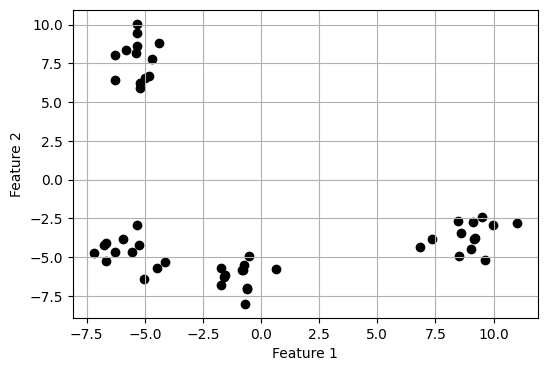

In [ ]:
plt.figure(figsize=(6, 4))
plt.scatter(X[:, 0], X[:, 1], color='black')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid(True)
plt.show()

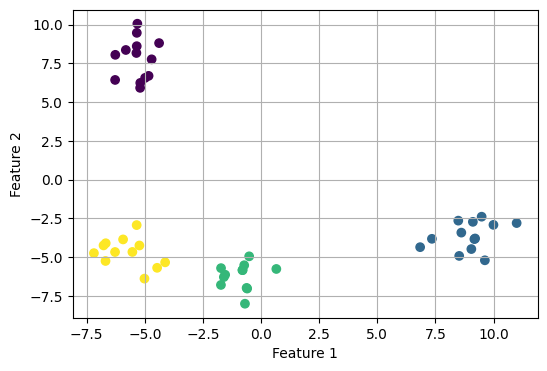

In [ ]:
plt.figure(figsize=(6, 4))
plt.scatter(X[:, 0], X[:, 1], c=y)
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid(True)
plt.show()

clusters: [[11, 39, 44, 45], [1, 3, 4, 9, 12, 23, 26, 29, 32, 34, 37, 43, 47], [0, 2, 5, 6, 8, 10, 13, 15, 16, 18, 19, 20, 21, 22, 24, 25, 27, 28, 30, 31, 33, 35, 36, 40, 42, 46, 48, 49], [7, 14, 17, 38, 41]]


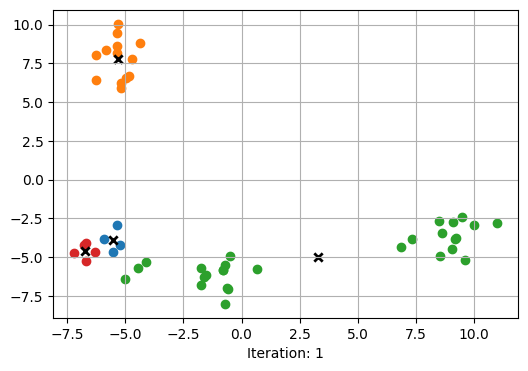

clusters: [[0, 11, 21, 27, 39, 42, 44, 45, 46, 48], [1, 3, 4, 9, 12, 23, 26, 29, 32, 34, 37, 43, 47], [2, 5, 6, 10, 13, 15, 16, 18, 19, 20, 22, 24, 25, 28, 30, 31, 33, 35, 36, 40, 49], [7, 8, 14, 17, 38, 41]]


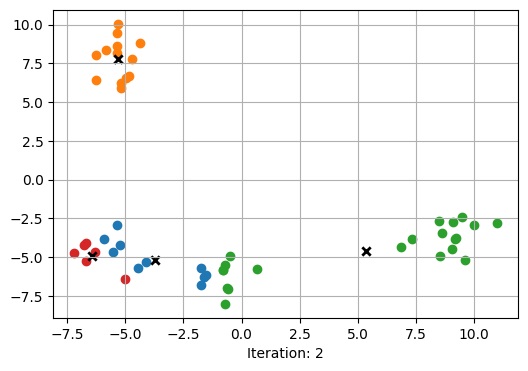

clusters: [[0, 2, 5, 8, 10, 18, 21, 27, 31, 36, 40, 42, 46, 48, 49], [1, 3, 4, 9, 12, 23, 26, 29, 32, 34, 37, 43, 47], [6, 13, 15, 16, 19, 20, 22, 24, 25, 28, 30, 33, 35], [7, 11, 14, 17, 38, 39, 41, 44, 45]]


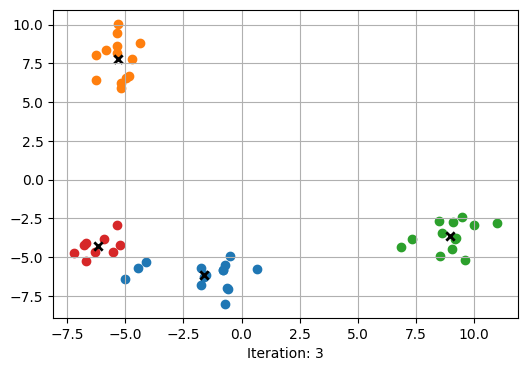

clusters: [[0, 2, 5, 10, 18, 21, 27, 31, 36, 40, 46, 49], [1, 3, 4, 9, 12, 23, 26, 29, 32, 34, 37, 43, 47], [6, 13, 15, 16, 19, 20, 22, 24, 25, 28, 30, 33, 35], [7, 8, 11, 14, 17, 38, 39, 41, 42, 44, 45, 48]]


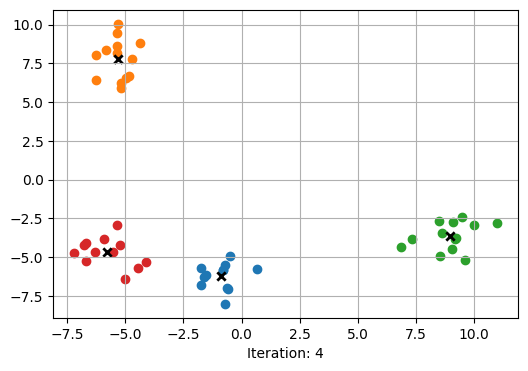

clusters: [[0, 2, 5, 10, 18, 21, 27, 31, 36, 40, 46, 49], [1, 3, 4, 9, 12, 23, 26, 29, 32, 34, 37, 43, 47], [6, 13, 15, 16, 19, 20, 22, 24, 25, 28, 30, 33, 35], [7, 8, 11, 14, 17, 38, 39, 41, 42, 44, 45, 48]]


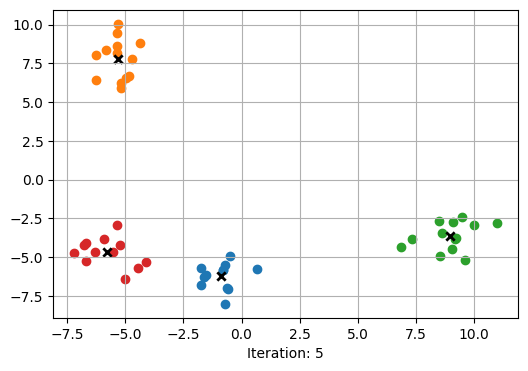

In [ ]:
k = KMeans(K=n_clusters, max_iters=150, plot_steps=True, random_state = 3)
y_pred = k.fit(X)

In [ ]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

ari = adjusted_rand_score(y, y_pred)
nmi = normalized_mutual_info_score(y, y_pred)

print(f"ARI: {ari:.2f}")
print(f"NMI: {nmi:.2f}")

ARI: 1.00
NMI: 1.00


### Where K-Means Struggles

In [ ]:
X = np.array([
    # Face outline
    [-5,0],[-4.9,1],[-4.7,2],[-4.3,3],[-3.7,3.9],[-3,4.5],[-2,4.8],[-1,5],[0,5],
    [1,5],[2,4.8],[3,4.5],[3.7,3.9],[4.3,3],[4.7,2],[4.9,1],[5,0],
    [4.9,-1],[4.7,-2],[4.3,-3],[3.7,-3.9],[3,-4.5],[2,-4.8],[1,-5],[0,-5],
    [-1,-5],[-2,-4.8],[-3,-4.5],[-3.7,-3.9],[-4.3,-3],[-4.7,-2],[-4.9,-1],

    # Left eye - dense cluster
    [-2.7,2.5],[-2.6,2.7],[-2.5,2.9],[-2.3,3.0],[-2.1,2.9],[-2.0,2.7],
    [-2.0,2.5],[-2.1,2.3],[-2.3,2.2],[-2.5,2.3],[-2.7,2.5],

    # Right eye - dense cluster
    [2.0,2.5],[2.0,2.7],[2.1,2.9],[2.3,3.0],[2.5,2.9],[2.6,2.7],
    [2.7,2.5],[2.5,2.3],[2.3,2.2],[2.1,2.3],[2.0,2.5],

    # Smile - dense curved cluster
    [-3,-1],[-2.8,-1.4],[-2.5,-1.8],[-2.2,-2.1],[-1.8,-2.4],[-1.4,-2.7],
    [-1,-2.9],[-0.5,-3.1],[0,-3.2],[0.5,-3.1],[1,-2.9],[1.4,-2.7],
    [1.8,-2.4],[2.2,-2.1],[2.5,-1.8],[2.8,-1.4],[3,-1]
])

y = np.array([0]*32 + [1]*11 + [2]*11 + [3]*17)


n_clusters = len(np.unique(y))
print(f'X.shape: {X.shape}')
print(f'y.shape: {y.shape}')
print(f'n_clusters: {n_clusters}')


X.shape: (71, 2)
y.shape: (71,)
n_clusters: 4


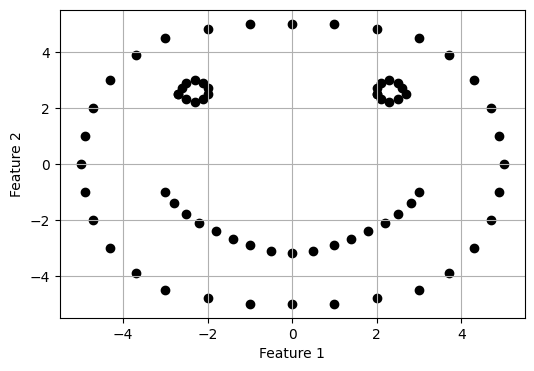

In [ ]:
plt.figure(figsize=(6, 4))
plt.scatter(X[:, 0], X[:, 1], color='black')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid(True)
plt.show()

clusters: [[14, 15, 16, 17, 18, 19, 20, 21, 22, 66, 67, 68, 69, 70], [2, 3, 4, 5, 6, 7, 8, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42], [9, 10, 11, 12, 13, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 23, 24, 25, 26, 27, 28, 29, 30, 31, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65]]


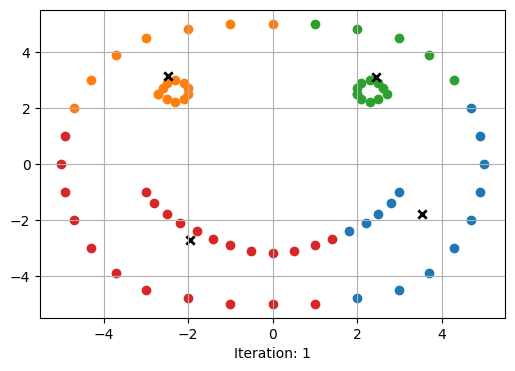

clusters: [[15, 16, 17, 18, 19, 20, 21, 22, 64, 65, 66, 67, 68, 69, 70], [0, 1, 2, 3, 4, 5, 6, 7, 8, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42], [9, 10, 11, 12, 13, 14, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [23, 24, 25, 26, 27, 28, 29, 30, 31, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63]]


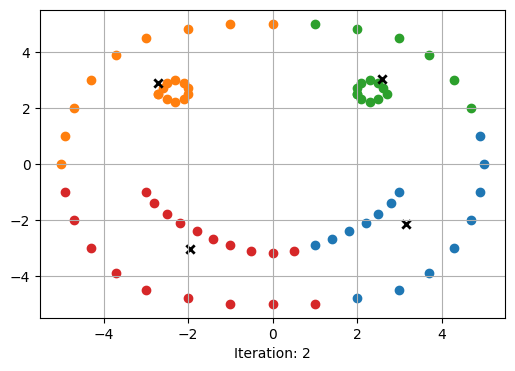

clusters: [[16, 17, 18, 19, 20, 21, 22, 64, 65, 66, 67, 68, 69, 70], [0, 1, 2, 3, 4, 5, 6, 7, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42], [8, 9, 10, 11, 12, 13, 14, 15, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [23, 24, 25, 26, 27, 28, 29, 30, 31, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63]]


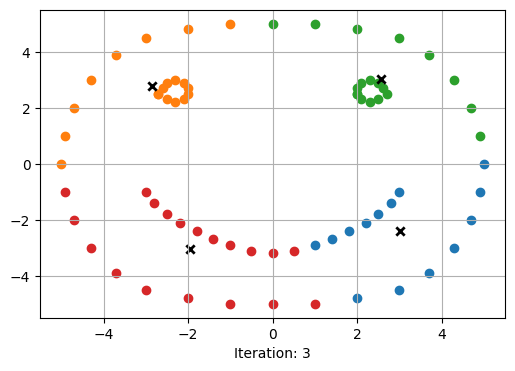

clusters: [[16, 17, 18, 19, 20, 21, 22, 23, 64, 65, 66, 67, 68, 69, 70], [0, 1, 2, 3, 4, 5, 6, 7, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42], [8, 9, 10, 11, 12, 13, 14, 15, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [24, 25, 26, 27, 28, 29, 30, 31, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63]]


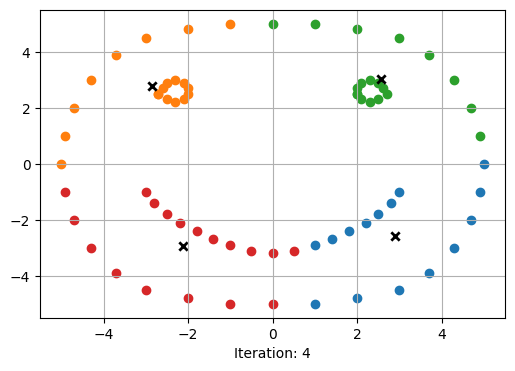

clusters: [[16, 17, 18, 19, 20, 21, 22, 23, 63, 64, 65, 66, 67, 68, 69, 70], [0, 1, 2, 3, 4, 5, 6, 7, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42], [8, 9, 10, 11, 12, 13, 14, 15, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [24, 25, 26, 27, 28, 29, 30, 31, 54, 55, 56, 57, 58, 59, 60, 61, 62]]


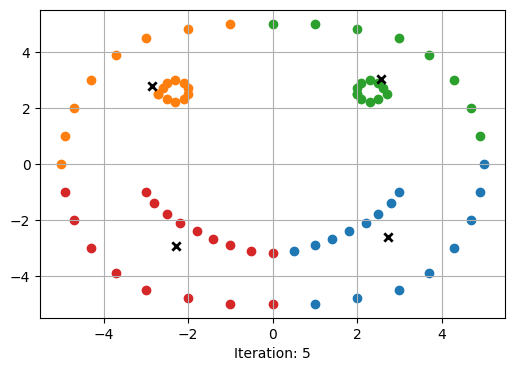

clusters: [[16, 17, 18, 19, 20, 21, 22, 23, 63, 64, 65, 66, 67, 68, 69, 70], [0, 1, 2, 3, 4, 5, 6, 7, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42], [8, 9, 10, 11, 12, 13, 14, 15, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [24, 25, 26, 27, 28, 29, 30, 31, 54, 55, 56, 57, 58, 59, 60, 61, 62]]


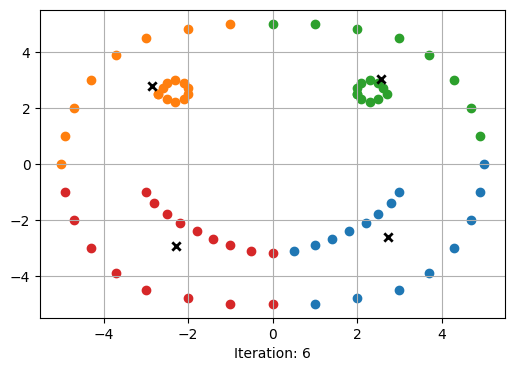

In [ ]:
k = KMeans(K=n_clusters, max_iters=150, plot_steps=True, random_state = 3)
y_pred = k.fit(X)

In [ ]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

ari = adjusted_rand_score(y, y_pred)
nmi = normalized_mutual_info_score(y, y_pred)

print(f"ARI: {ari:.2f}")
print(f"NMI: {nmi:.2f}")


ARI: 0.22
NMI: 0.45


### K-Means with Iris Dataset

In [ ]:
from sklearn.datasets import load_iris
iris = load_iris()

X = iris.data
y = iris.target

n_clusters = len(np.unique(y))
print(f'X.shape: {X.shape}')
print(f'y.shape: {y.shape}')
print(f'n_clusters: {n_clusters}')

X.shape: (150, 4)
y.shape: (150,)
n_clusters: 3


In [ ]:
org_clusters = [[] for _ in range(n_clusters)]
for idx, sample in enumerate(X):
    org_clusters[y[idx]].append(idx)
print(org_clusters)

[[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49], [50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99], [100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149]]


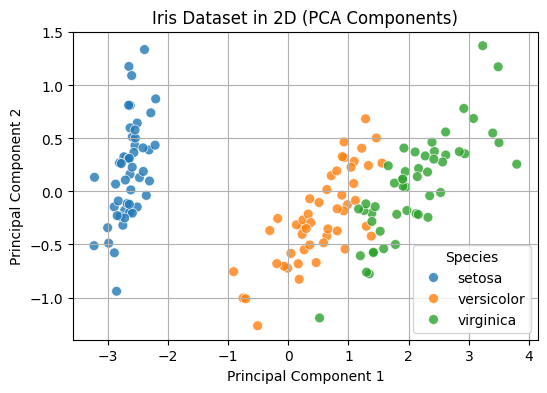

In [ ]:
# Visualize the original dataset using PCA for 2D representation
from sklearn.decomposition import PCA
import seaborn as sns
pca_viz = PCA(n_components=2, random_state=42)
X_pca_viz = pca_viz.fit_transform(X)

plt.figure(figsize=(6, 4))
sns.scatterplot(
    x=X_pca_viz[:, 0],
    y=X_pca_viz[:, 1],
    hue=iris.target_names[y],
    palette='tab10',
    s=50,
    alpha=0.8
)
plt.title('Iris Dataset in 2D (PCA Components)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.grid(True)
plt.legend(title='Species')
plt.show()

In [ ]:
k = KMeans(K=n_clusters, max_iters=150, plot_steps=False, random_state = 3)
y_pred = k.fit(X)

clusters: [[1, 2, 3, 8, 9, 12, 13, 22, 25, 29, 30, 34, 35, 38, 41, 42, 45, 47], [0, 4, 5, 6, 7, 10, 11, 14, 15, 16, 17, 18, 19, 20, 21, 23, 24, 26, 27, 28, 31, 32, 33, 36, 37, 39, 40, 43, 44, 46, 48, 49, 57, 59, 60, 64, 79, 80, 81, 93, 98], [50, 51, 52, 53, 54, 55, 56, 58, 61, 62, 63, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 94, 95, 96, 97, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149]]
clusters: [[0, 1, 2, 3, 4, 6, 7, 8, 9, 11, 12, 13, 22, 25, 29, 30, 34, 35, 37, 38, 40, 41, 42, 45, 47, 49], [5, 10, 14, 15, 16, 17, 18, 19, 20, 21, 23, 24, 26, 27, 28, 31, 32, 33, 36, 39, 43, 44, 46, 48, 57, 60, 93, 98], [50, 51, 52, 53, 54, 55, 56, 58, 59, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 8

In [ ]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

ari = adjusted_rand_score(y, y_pred)
nmi = normalized_mutual_info_score(y, y_pred)

print(f"ARI: {ari:.2f}")
print(f"NMI: {nmi:.2f}")


ARI: 0.42
NMI: 0.59


## Homework:


### A. K-Means with Immediate Update
**Algorithm (K-Means with Immediate Update)**:
1. Select a value for K (the number of clusters).
2. Initialize the cluster centers with K random data points.
3. Decide the cluster memberships of each data points by assigning them to the nearest cluster center. Immediately re-estimate the cluster centers after each object is moved to a new cluster.
4. Repeat 3 until none of the N data points changed membership in the last iteration.

### B. K-Means++
**Algorithm (K-Means++)**:
1. Select a value for K (the number of clusters).
1. Select the first cluster center randomly from the N data points.
1. For each remaining data point, calculate its squared distance to the nearest existing cluster center. Select the next centroid with a probability proportional to the squared distance.
1. Repeat 3 until K cluster centers have been selected
1. Decide the cluster memberships of the N data points by assigning them to the nearest cluster center.
1. Re-estimate the K cluster centers.
1. Repeat 3 and 4 until none of the N data points changed membership in the last iteration.


### Pseudocode for K-Means
```
CLASS KMeans:

    FUNCTION __init__(k, max_iterations):
        SET self.k = k
        SET self.max_iterations = max_iterations
        SET self.centroids = empty

    FUNCTION distance(point1, point2):
        SET sum = 0
        FOR i = 0 TO number_of_features - 1:
            sum = sum + (point1[i] - point2[i])²
        RETURN √sum


    FUNCTION fit(X):
        self.centroids = Select k random points as initial centroids

        FOR iteration = 1 TO self.max_iterations:
            labels = empty list
            FOR each point IN X:
                min_distance = infinity
                closest_cluster = 0
                FOR cluster = 0 TO self.k - 1:
                    d = self.distance(
                        point,
                        self.centroids[cluster]
                    )
                    IF d < min_distance:
                        min_distance = d
                        closest_cluster = cluster
                ADD closest_cluster TO labels

            new_centroids = empty list
            FOR cluster = 0 TO self.k - 1:
                cluster_points = all points whose label == cluster
                new_centroid = mean(cluster_points)
                ADD new_centroid TO new_centroids

            IF new_centroids == self.centroids:
                BREAK
            self.centroids = new_centroids

        self.labels = labels
        RETURN self.labels

```